In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

tf.random.set_seed(1)
np.random.seed(1)

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print('train:', x_train_full.shape, y_train_full.shape)
print('test :', x_test.shape, y_test.shape)

train: (60000, 28, 28) (60000,)
test : (10000, 28, 28) (10000,)


In [3]:
x_train, y_train = x_train_full[:50000], y_train_full[:50000]
x_valid, y_valid = x_train_full[50000:], y_train_full[50000:]

x_train = x_train / 255.0
x_valid = x_valid / 255.0
x_test = x_test / 255.0

print('train:', x_train.shape, '/ valid:', x_valid.shape, '/ test:', x_test.shape)
print('pixel range:', x_train.min(), '~', x_train.max())

train: (50000, 28, 28) / valid: (10000, 28, 28) / test: (10000, 28, 28)
pixel range: 0.0 ~ 1.0


In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

/opt/miniconda3/envs/mldl/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [6]:
history = model.fit(x_train, y_train,
                    batch_size=100,
                    epochs=20,
                    validation_data=(x_valid, y_valid),
                    verbose=1)

Epoch 1/20


  1/500 ━━━━━━━━━━━━━━━━━━━━ 2:22 286ms/step - accuracy: 0.0600 - loss: 2.3629

 24/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5460 - loss: 1.5340    

 48/500 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6580 - loss: 1.1794

 72/500 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7117 - loss: 0.9994

 96/500 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7446 - loss: 0.8871

... (531 outputs left out)

460/500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9972 - loss: 0.0090

477/500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9972 - loss: 0.0090

496/500 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9972 - loss: 0.0090

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9976 - loss: 0.0084 - val_accuracy: 0.9809 - val_loss: 0.1120


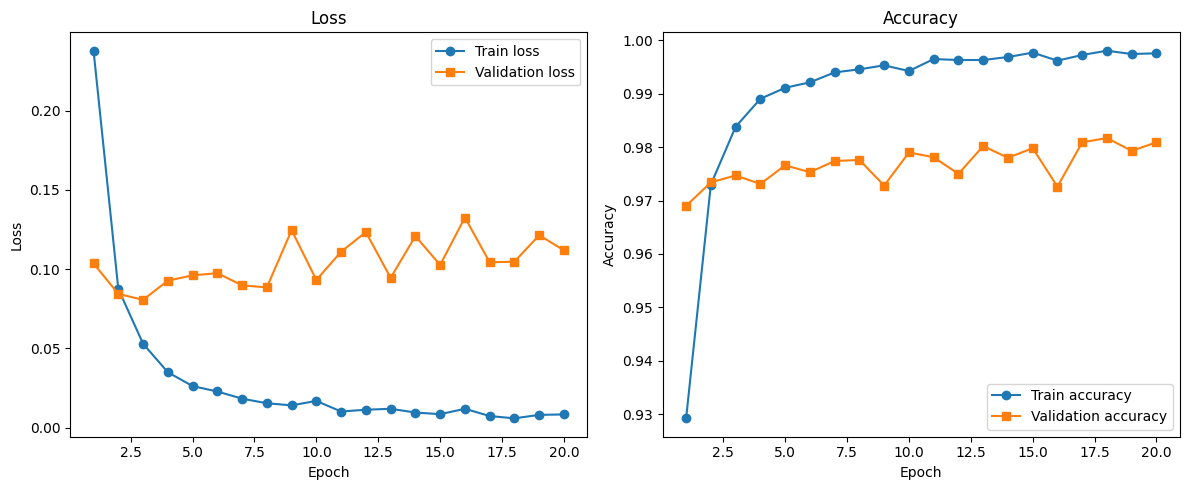

In [7]:
hist = history.history
epochs = range(1, len(hist['loss']) + 1)

fig = plt.figure(figsize=(12, 5))

ax = fig.add_subplot(1, 2, 1)
ax.plot(epochs, hist['loss'], 'o-', label='Train loss')
ax.plot(epochs, hist['val_loss'], 's-', label='Validation loss')
ax.set_title('Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend()

ax = fig.add_subplot(1, 2, 2)
ax.plot(epochs, hist['accuracy'], 'o-', label='Train accuracy')
ax.plot(epochs, hist['val_accuracy'], 's-', label='Validation accuracy')
ax.set_title('Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend()

plt.tight_layout()
plt.show()

In [8]:
best_epoch = int(np.argmin(hist['val_loss'])) + 1
print('Lowest validation loss : %.4f (epoch %d)' % (min(hist['val_loss']), best_epoch))
print('Final train loss       : %.4f' % hist['loss'][-1])
print('Final validation loss  : %.4f' % hist['val_loss'][-1])
print('Final train accuracy   : %.4f' % hist['accuracy'][-1])
print('Final valid accuracy   : %.4f' % hist['val_accuracy'][-1])

Lowest validation loss : 0.0807 (epoch 3)
Final train loss       : 0.0084
Final validation loss  : 0.1120
Final train accuracy   : 0.9976
Final valid accuracy   : 0.9809


In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print('Test loss     : %.4f' % test_loss)
print('Test accuracy : %.4f (%.2f%%)' % (test_acc, test_acc * 100))

Test loss     : 0.1058
Test accuracy : 0.9810 (98.10%)
